Exact GP using KeOPS for rapid kernel operations.

In [ ]:
%reload_ext autoreload
%autoreload 2
import os
import sys
sys.path.insert(0, os.path.abspath('../src'))
import pandas as pd
import geopandas as gpd
from pathlib import Path
import numpy as np
import fiona
import matplotlib.pyplot as plt
import contextily as cx
from shapely import contains_xy
from scipy.spatial import Delaunay


import processing_help
import tqdm
import rasterio
from rasterio.warp import transform_bounds
from rasterio.transform import from_origin
from rasterio.features import geometry_mask

import torch

import gpytorch
from gpytorch.constraints import Interval, GreaterThan
from gpytorch.priors import GammaPrior

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4070
Memory: 12.5 GB


In [ ]:
WORK_DIR = Path('/mnt/teamgroup/AutoDBM/Public')
MBES = WORK_DIR / 'Multibeam_Validation_Points_For_Distribution'
SBES = WORK_DIR / 'Synthetic_Singlebeam_Surveys_For_Distribution'
CRS = pd.read_csv(WORK_DIR / 'survey_CRS_list.csv')

mbes = list((WORK_DIR / 'Multibeam_Validation_Points_For_Distribution').glob('*.csv'))
sbes = list((WORK_DIR / 'Synthetic_Singlebeam_Surveys_For_Distribution').glob('*.csv'))
crs_data = WORK_DIR / 'survey_CRS_list.csv'

geojson = Path(os.getcwd()).parent / 'shapefiles' / 'National_Channel_Framework_-6742069550782745925.geojson'
ncf = gpd.read_file(geojson)

In [3]:
# TODO: Go through and build a dataset off these 30 which include congressionally authorized depths
# this would allow us to better estimate dredge cuts and copmare across the interpolation methods

# NOTE: authorized depths probably vary between the individual reaches within each area


# Build a boundary catalog from SurveyJob layers, then match each survey to the best boundary by SurveyId
data_pairs = {}

def _norm(s):
    return "".join(ch for ch in str(s).upper() if ch.isalnum())

def _tokens(s):
    return {t for t in str(s).upper().replace("-", "_").split("_") if t}

# 1) Read all boundary candidates once
boundary_catalog = []
for gdb_file in WORK_DIR.glob("*/*.gdb"):
    try:
        sj = gpd.read_file(gdb_file, layer="SurveyJob")
    except Exception:
        continue

    if "SurveyId" not in sj.columns or sj.empty:
        continue

    # keep one record per SurveyId (first occurrence)
    for sid, grp in sj.groupby("SurveyId", dropna=True):
        boundary_catalog.append({
            "survey_id": str(sid),
            "survey_norm": _norm(sid),
            "survey_tokens": _tokens(sid),
            "gdb_file": gdb_file,
            "boundary": grp.copy()
        })

# 2) Match each survey from CRS table to best boundary
for _, items in pd.read_csv(crs_data).iterrows():
    survey = items["Survey"]

    sbes_match = [p for p in sbes if survey in str(p)]
    mbes_match = [p for p in mbes if survey in str(p)]
    if not sbes_match or not mbes_match:
        print(f"Missing SBES/MBES file for: {survey}")
        continue

    s_norm = _norm(survey)
    s_tokens = _tokens(survey)

    # exact normalized SurveyId match first
    exact = [c for c in boundary_catalog if c["survey_norm"] == s_norm]

    if exact:
        best = exact[0]
    else:
        # fallback: token overlap score
        scored = []
        for c in boundary_catalog:
            inter = len(s_tokens & c["survey_tokens"])
            denom = max(1, len(s_tokens))
            score = inter / denom
            scored.append((score, c))
        scored.sort(key=lambda x: x[0], reverse=True)
        best = scored[0][1] if scored and scored[0][0] > 0 else None

    if best is None:
        print(f"No boundary found for: {survey}")
        continue

    boundary = best["boundary"]
    data_pairs[survey] = [
        sbes_match[0],
        mbes_match[0],
        boundary,
    ]

    print(f"{survey} -> {best['survey_id']} ({best['gdb_file'].name})")

AK_08_WES_20160318_CS_FULL -> AK_08_WES_20160318_CS (AK_08_WES_20160318_CS.gdb)
BR_02_JEC_20260211_CS -> BR_02_JEC_20260211_CS (BR_02_JEC_20260211_CS.gdb)
CB_02_CB2_20260202_CS_A -> CB_02_CB2_20260202_CS (CB_02_CB2_20260202_CS.gdb)
CC_05_HLQ_20260205_XC -> CC_05_HLQ_20260205_XC (CC_05_HLQ_20260205_XC.gdb)
CH_02_CHL_20220210_CS_FULL -> CH_02_CHL_20220210_CS (CH_02_CHL_20220210_CS.gdb)
CL_02_UDS_20260305_CS_A -> CL_02_UDS_20260305_CS (CL_02_UDS_20260305_CS.gdb)
CR_ND_BL5_20220301_CS_102_103_SORT -> CR_ND_BL5_20220301_CS_102_103_SORT (CR_ND_BL5_20220301_CS_102_103_SORT.gdb)
DU_02_EWW_20260211_CS_E_12_6_1_67 -> DU_02_EWW_20260211_CS_E_12_6_1_67 (DU_02_EWW_20260211_CS_E_12_6_1_67.gdb)
FR_6A_SCL_20240401_CS -> FR_6A_SCL_20240401_CS (FR_6A_SCL_20240401_CS.gdb)
GH_03_COC_20251202_CS_E_5_13_439 -> GH_03_COC_20251202_CS_E_5_13_439 (GH_03_COC_20251202_CS_E_5_13_439.gdb)
GW_68_CSL_20250909_CS_3X3_A -> GW_68_CSL_20250909_CS_3X3 (GW_68_CSL_20250909_CS_3X3.gdb)
IL_LA_MVR_20251118_CS_14001420_25D_A ->

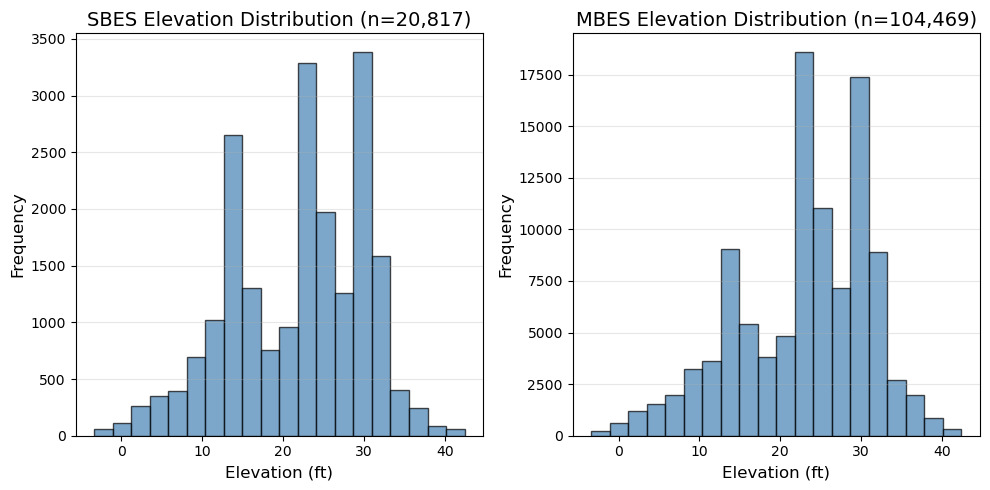


SBES Elevation Statistics (n=20,817):
  Mean: 21.88 ft
  Std: 8.31 ft
  Min: -3.33 ft
  Max: 42.44 ft

MBES Elevation Statistics (n=104,469):
  Mean: 22.99 ft
  Std: 8.21 ft
  Min: -3.39 ft
  Max: 42.44 ft


In [4]:
survey = list(data_pairs.keys())[0]
# survey = "CL_02_UDS_20260305_CS_A"

test_pair = data_pairs[survey]
sbes_data = pd.read_csv(test_pair[0])
mbes_data = pd.read_csv(test_pair[1])
boundary = test_pair[2]
data_crs = boundary.crs

sbes_gdf = gpd.GeoDataFrame(
        sbes_data.copy(),
        geometry=gpd.points_from_xy(sbes_data["X_ft"], sbes_data["Y_ft"]),
        crs=data_crs
    )

mbes_gdf = gpd.GeoDataFrame(
        mbes_data.copy(),
        geometry=gpd.points_from_xy(mbes_data["X_ft"], mbes_data["Y_ft"]),
        crs=data_crs
    )

OUT_DIR = WORK_DIR / survey
os.makedirs(OUT_DIR, exist_ok=True)

sbes_x = sbes_gdf.X_ft
sbes_y = sbes_gdf.Y_ft
sbes_z = sbes_gdf.Elevation_ft * -1

mbes_x = mbes_gdf.X_ft
mbes_y = mbes_gdf.Y_ft
mbes_z = mbes_gdf.Elevation_ft * -1

fig, ax = plt.subplots(1,2, figsize=(10, 5))

# Histogram for sbes_z
ax[0].hist(sbes_z, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax[0].set_xlabel('Elevation (ft)', fontsize=12)
ax[0].set_ylabel('Frequency', fontsize=12)
ax[0].set_title(f'SBES Elevation Distribution (n={len(sbes_z):,})', fontsize=14)
ax[0].grid(axis='y', alpha=0.3)

# Histogram for mbes_z
ax[1].hist(mbes_z, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax[1].set_xlabel('Elevation (ft)', fontsize=12)
ax[1].set_ylabel('Frequency', fontsize=12)
ax[1].set_title(f'MBES Elevation Distribution (n={len(mbes_z):,})', fontsize=14)
ax[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\nSBES Elevation Statistics (n={len(sbes_z):,}):")
print(f"  Mean: {np.mean(sbes_z):.2f} ft")
print(f"  Std: {np.std(sbes_z):.2f} ft")
print(f"  Min: {np.min(sbes_z):.2f} ft")
print(f"  Max: {np.max(sbes_z):.2f} ft")

print(f"\nMBES Elevation Statistics (n={len(mbes_z):,}):")
print(f"  Mean: {np.mean(mbes_z):.2f} ft")
print(f"  Std: {np.std(mbes_z):.2f} ft")
print(f"  Min: {np.min(mbes_z):.2f} ft")
print(f"  Max: {np.max(mbes_z):.2f} ft")

## First, map the survey we are processing and visualize the histrogram of the soundings

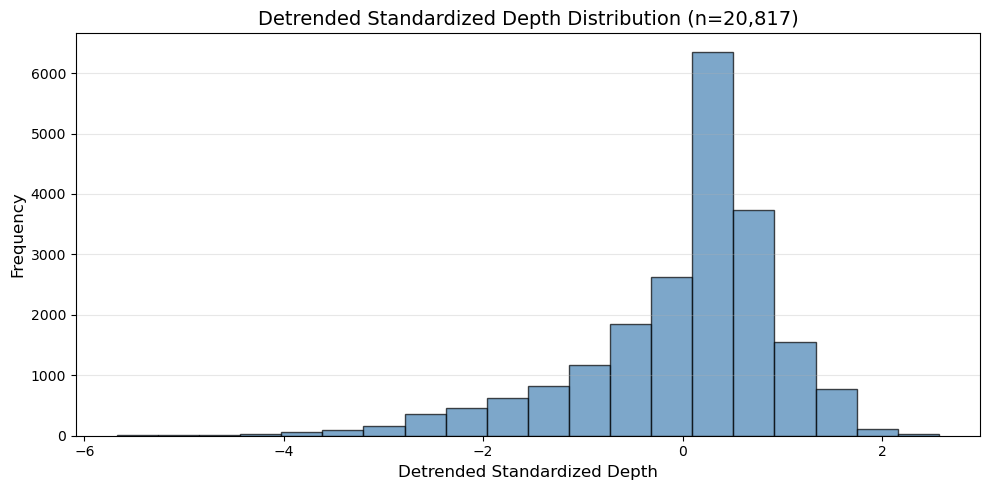

Detrended Standardized Depth Statistics (n=20,817):
  Mean: -0.00
  Std: 1.00
  Min: -5.67
  Max: 2.57


In [5]:
# TODO: implement a verde spline and look to see if it will better zero-mean the data compared to normalization
import verde as vd

chain = vd.Chain([
    ("reduce", vd.BlockMean(spacing=50)),   # 50ft spacing reuction for fitting the spline
    ("spline", vd.Spline(damping=1e-4)),
])
xy_raw = np.column_stack([sbes_x, sbes_y])

chain.fit((xy_raw[:, 0], xy_raw[:, 1]), sbes_z)
trend_pred = chain.predict((xy_raw[:, 0], xy_raw[:, 1]))   # evaluate at full resolution
residuals = sbes_z - trend_pred

residuals_norm = (residuals - np.mean(residuals)) / np.std(residuals)

fig, ax = plt.subplots(figsize=(10, 5))

# Histogram for residuals_norm
ax.hist(residuals_norm, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Detrended Standardized Depth', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Detrended Standardized Depth Distribution (n={len(residuals_norm):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Detrended Standardized Depth Statistics (n={len(residuals_norm):,}):")
print(f"  Mean: {np.mean(residuals_norm):.2f}")
print(f"  Std: {np.std(residuals_norm):.2f}")
print(f"  Min: {np.min(residuals_norm):.2f}")
print(f"  Max: {np.max(residuals_norm):.2f}")

## Develop KISS-GP for generating bathymetric surfaces from the singlebeam echosounder data

In [6]:
# should be 10 ft spatial resolution for the outputs
grid_res = 10.0 

# 1. Train on the full dataset
X_all = torch.as_tensor(xy_raw, dtype=torch.float32)
y_all = torch.as_tensor(residuals_norm, dtype=torch.float32)

# Standardize
# TODO: look into scaling with separate standardizations for X coords and Y coords
# the below is scaling using the mean and stddev from all XY coords
x_mean = X_all.mean(0)
x_std = X_all.std(0).clamp_min(1e-6)
X_all_scaled = (X_all - x_mean) / x_std

if torch.cuda.is_available():
    X_all_scaled = X_all_scaled.cuda().float()
    y_all = y_all.cuda().float()
xy_raw = np.asarray(xy_raw, dtype=np.float32)
x_min, x_max = float(xy_raw[:, 0].min()), float(xy_raw[:, 0].max())
y_min, y_max = float(xy_raw[:, 1].min()), float(xy_raw[:, 1].max())

nx = int(np.ceil((x_max - x_min) / grid_res)) + 1
ny = int(np.ceil((y_max - y_min) / grid_res)) + 1
x_grid = np.linspace(x_min, x_min + (nx - 1) * grid_res, nx, dtype=np.float32)
y_grid = np.linspace(y_min, y_min + (ny - 1) * grid_res, ny, dtype=np.float32)

transform = from_origin(
    x_min - grid_res / 2,
    y_max + grid_res / 2,
    grid_res, grid_res
)

grid_xx, grid_yy = np.meshgrid(x_grid, y_grid)  # shape (ny, nx) by default
grid_points = torch.stack([
    torch.tensor(grid_xx.flatten(), dtype=torch.float32),
    torch.tensor(grid_yy.flatten(), dtype=torch.float32)
], dim=1)

grid_points_s = (grid_points - x_mean.cpu()) / x_std.cpu()

In [7]:
# TODO: look into replacing matern_short with a polynomial, piecewise polynomial, or quadratic kernel for fine scale features

class GPRegressionModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super(GPRegressionModel, self).__init__(train_x, train_y, likelihood)

        self.mean_module = gpytorch.means.ConstantMean()

        ext = (train_x.max(dim=0).values - train_x.min(dim=0).values).detach().cpu()
        dmin, dmax = float(ext.min()), float(ext.max())

        target_variance = float(train_y.var())
        prior_concentration = 2.0
        prior_rate = prior_concentration / target_variance

        matern_short = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=1.5, ard_num_dims=2,
                lengthscale_constraint=Interval(1e-4, dmin * 0.10), 
            ), 
            outputscale_prior=GammaPrior(prior_concentration, prior_rate)
        )

        matern_long = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=2.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.10, dmax * 0.50),  
            ), 
            outputscale_prior=GammaPrior(prior_concentration, prior_rate)
        )

        # Hard coded grid_size. push as high as VRAM allows (e.g., 250, 300, or 400)
        self.covar_module = gpytorch.kernels.GridInterpolationKernel(
            matern_short + matern_long,
            num_dims=2, 
            grid_size=500 
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        # Only one covariance pass needed now
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

In [ ]:
# Constrained noise. If the model sees a small feature in the poin cloud, it may assume it is noice and parameterize to smooth over it
likelihood = gpytorch.likelihoods.GaussianLikelihood(
    noise_constraint=GreaterThan(1e-3), 
    noise_prior=GammaPrior(concentration=2.0, rate=4.65) 
)

model = GPRegressionModel(X_all_scaled, y_all, likelihood)

In [9]:
import linear_operator

num_epochs = 50

model = model.to(device)
likelihood = likelihood.to(device)

model.train()
likelihood.train()

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Exact GP marginal log likelihood
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

epochs_iter = tqdm.notebook.tqdm(range(num_epochs), desc="Epoch")
with gpytorch.settings.max_preconditioner_size(0), linear_operator.settings.max_cg_iterations(10000):
    for i in epochs_iter:
        optimizer.zero_grad()
        output = model(X_all_scaled)
        loss = -mll(output, y_all)
        loss.backward()
        optimizer.step()
        epochs_iter.set_postfix(loss=loss.item())

Epoch:   0%|          | 0/50 [00:00<?, ?it/s]

/home/clayc/git_repos/eHydroInterpolation/.pixi/envs/default/lib/python3.12/site-packages/linear_operator/utils/sparse.py:52: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  if nonzero_indices.storage():
/home/clayc/git_repos/eHydroInterpolation/.pixi/envs/default/lib/python3.12/site-packages/linear_operator/utils/sparse.py:67: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:78.)
  res = cls(index_tensor, value_tensor, interp_size)
/home/clayc/git_repos/eHydroInterpolation/.pixi/envs/default/lib/python3.12/site-packages/linear_operator/utils/sparse.py:67: U

In [10]:
import gc

model.eval()
likelihood.eval()

gc.collect()
torch.cuda.empty_cache()

chunk_size = 10000 
pred_means = []
pred_stds = []

with torch.no_grad(), gpytorch.settings.fast_pred_var(), linear_operator.settings.max_cg_iterations(10000):
    # Loop through the prediction grid in chunks
    for i in range(0, grid_points_s.shape[0], chunk_size):
        # Extract the chunk and send it to the GPU
        chunk = grid_points_s[i : i + chunk_size].to(device)
        
        # Predict on just this chunk (using the latent function, no likelihood)
        latent_preds = model(chunk)
        
        # Immediately move results back to CPU RAM to keep GPU VRAM empty
        pred_means.append(latent_preds.mean.cpu())
        pred_stds.append(latent_preds.stddev.cpu())

# Stitch the chunks back together into single arrays
surface_mean = torch.cat(pred_means).numpy()
surface_uncertainty = torch.cat(pred_stds).numpy()

/home/clayc/git_repos/eHydroInterpolation/.pixi/envs/default/lib/python3.12/site-packages/linear_operator/utils/linear_cg.py:339: NumericalWarning: CG terminated in 10000 iterations with average residual norm 1.098101019859314 which is larger than the tolerance of 0.01 specified by linear_operator.settings.cg_tolerance. If performance is affected, consider raising the maximum number of CG iterations by running code in a linear_operator.settings.max_cg_iterations(value) context.
  warnings.warn(


In [11]:
# Convert back to real units
z_grid = surface_mean * np.std(residuals) + np.mean(residuals)
z_uncertainty = surface_uncertainty * np.std(residuals)

trend_pred_grid = chain.predict((grid_points[:, 0].numpy(), grid_points[:, 1].numpy()))
z_grid_true = z_grid + trend_pred_grid

In [ ]:
# Reshape to 2D grid
z_surface = z_grid_true.reshape(grid_xx.shape)
z_unc_surface = z_uncertainty.reshape(grid_xx.shape)

grid_np = grid_points.numpy()
polygon_mask = contains_xy((boundary).union_all(), grid_np[:, 0], grid_np[:, 1])
delaunay_hull = Delaunay(xy_raw)
delaunay_flat_mask = delaunay_hull.find_simplex(grid_np) >= 0
# delaunay_mask = delaunay_flat_mask.reshape(grid_xx.shape)
mask = delaunay_flat_mask & polygon_mask

# Apply mask to predictions.
z_grid_masked = z_grid_true
z_unc_masked = z_uncertainty
z_grid_masked[~mask] = np.nan
z_unc_masked[~mask] = np.nan

# Reshape back to 2D arrays aligned with transform/from_origin.
z_surface_masked = z_grid_masked.reshape(grid_xx.shape)
z_unc_surface_masked = z_unc_masked.reshape(grid_xx.shape)
 
z_raster = np.flipud(z_surface_masked).astype(np.float32)
z_unc_raster = np.flipud(z_unc_surface_masked).astype(np.float32)

In [13]:
# export bathymetric surface

meta = {
    'driver': 'GTiff',
    'height': z_raster.shape[0],
    'width': z_raster.shape[1],
    'count': 1,
    'dtype': 'float32',
    'crs': data_crs,
    'transform': transform,
    'nodata': -9999,
    'tiled': True,
    'blockxsize': 512,
    'blockysize': 512,
    'compress': 'deflate',
    'predictor': 3,
    'zlevel': 6
}

with rasterio.open(OUT_DIR / 'KISSGP_depth.tif', 'w', **meta) as dst:
    dst.write(z_raster, 1)
    dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)

with rasterio.open(OUT_DIR / 'KISSGP_uncertainty.tif', 'w', **meta) as dst:
    dst.write(z_unc_raster, 1)
    dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)

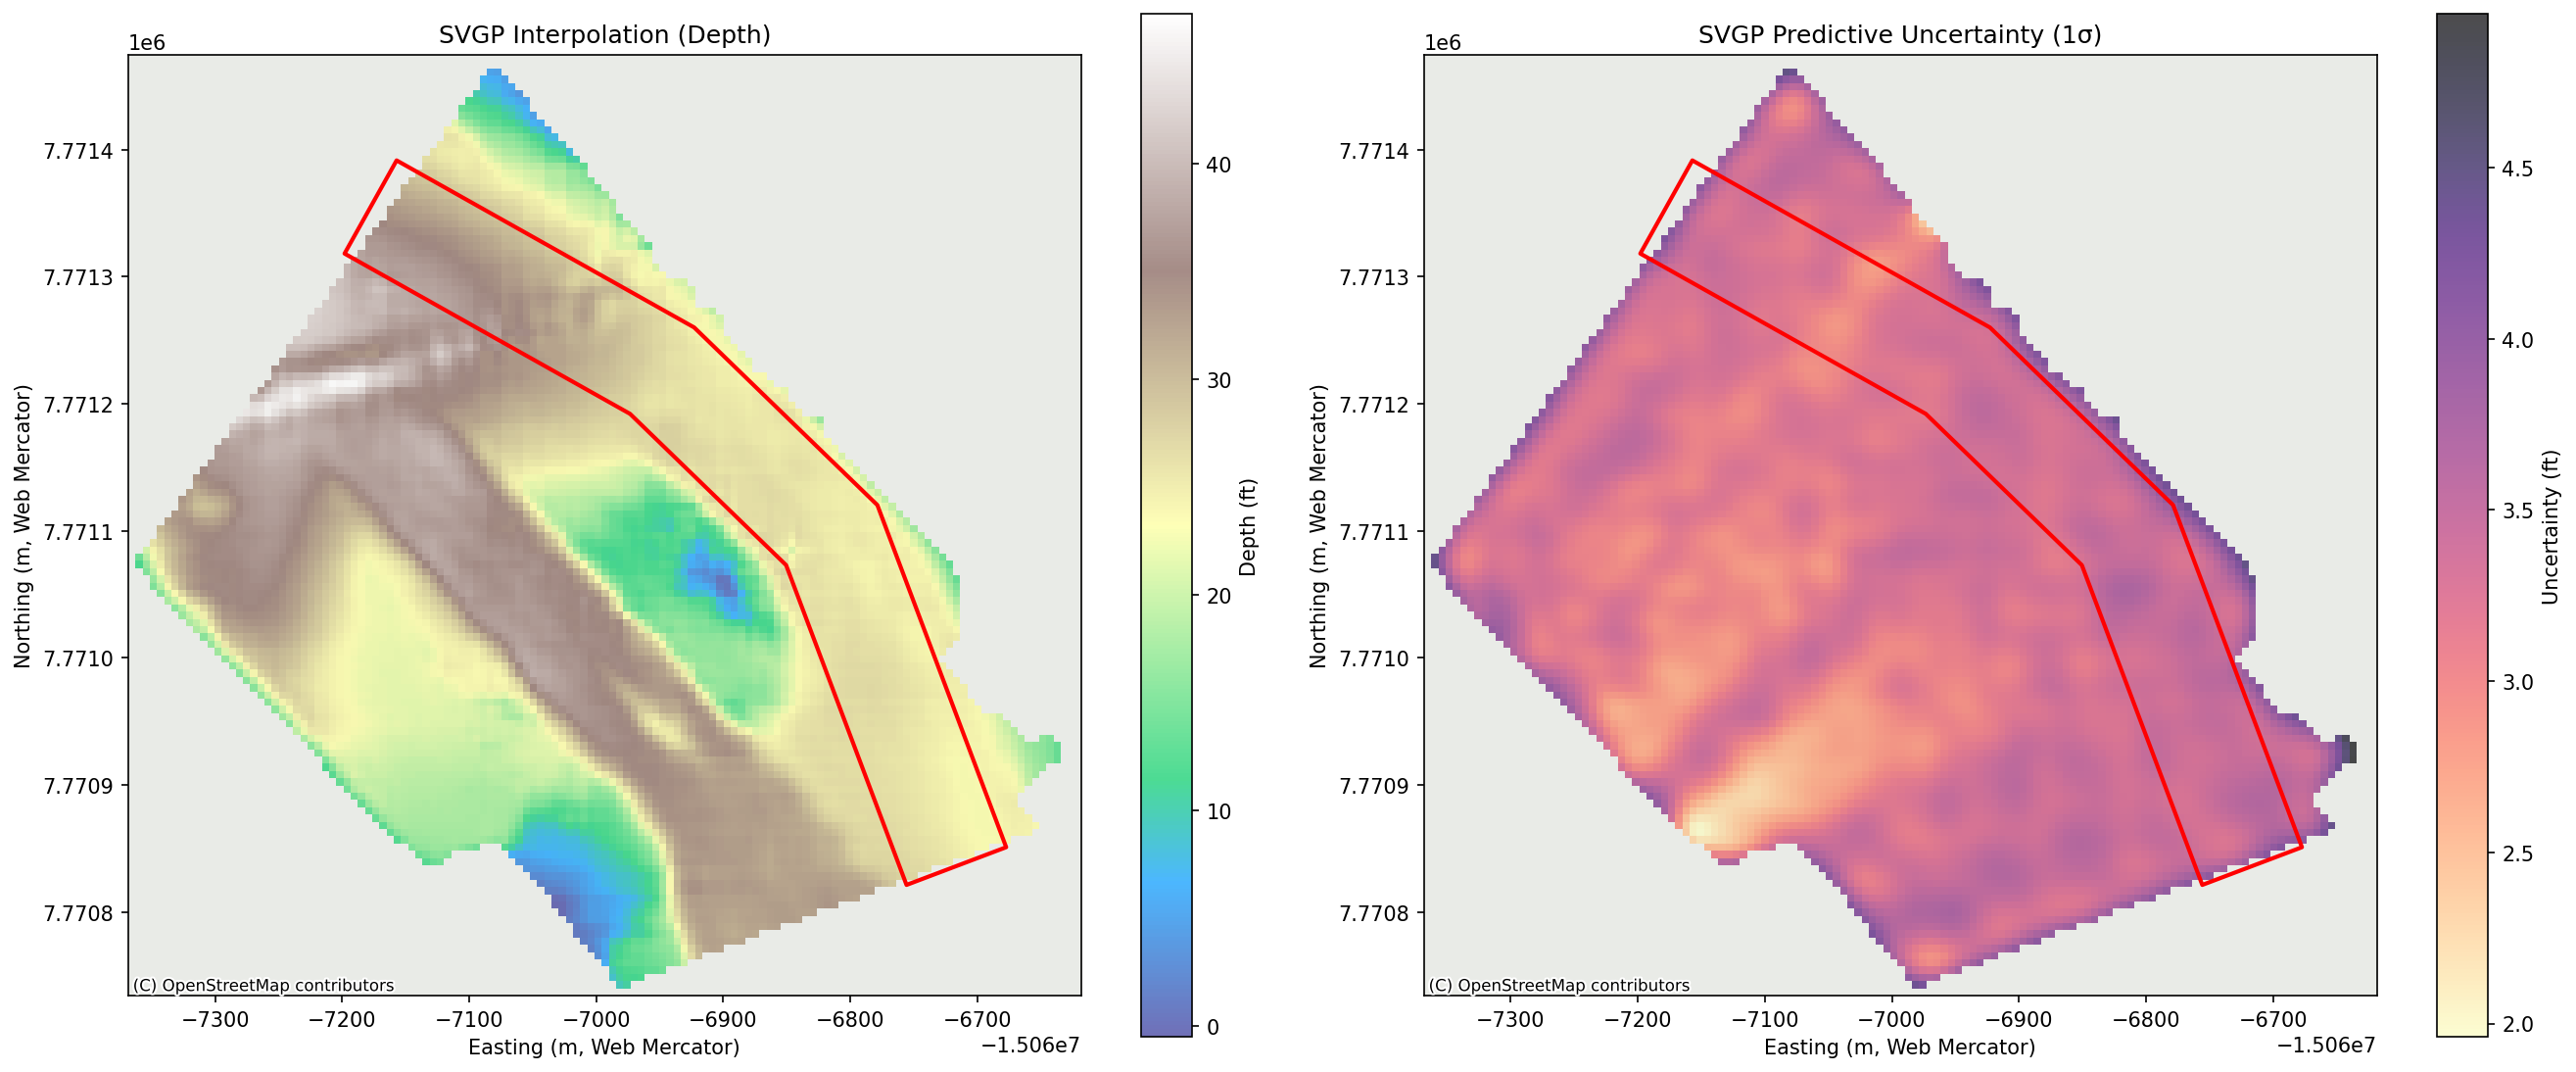

In [14]:
survey_polygons_3857 = boundary.to_crs(epsg=3857)
ncf_polygons_3857 = ncf.to_crs(epsg=3857)

# Reproject raster extent from survey CRS to Web Mercator.
x_min_3857, y_min_3857, x_max_3857, y_max_3857 = transform_bounds(
    data_crs, "EPSG:3857", x_min, y_min, x_max, y_max
)
extent_3857 = [x_min_3857, x_max_3857, y_min_3857, y_max_3857]

# plot predictions and prediction uncertainty
fig, axes = plt.subplots(1, 2, figsize=(18, 9), dpi=150)

im1 = axes[0].imshow(
    np.flipud(z_raster), origin="lower", extent=extent_3857,
    cmap="terrain", alpha=0.7, zorder=2
)

ncf_polygons_3857.plot(ax=axes[0], facecolor='none', edgecolor='red',
                       linewidth=2, zorder=3)
cx.add_basemap(axes[0], source=cx.providers.OpenStreetMap.Mapnik,
               crs="EPSG:3857", zorder=1)
axes[0].set_xlim(extent_3857[0], extent_3857[1])
axes[0].set_ylim(extent_3857[2], extent_3857[3])
axes[0].set_title("SVGP Interpolation (Depth)")
axes[0].set_xlabel("Easting (m, Web Mercator)")
axes[0].set_ylabel("Northing (m, Web Mercator)")
fig.colorbar(im1, ax=axes[0], label="Depth (ft)", shrink=0.8)


im2 = axes[1].imshow(
    np.flipud(z_unc_raster), origin="lower", extent=extent_3857,
    cmap="magma_r", alpha=0.7, zorder=2
)

ncf_polygons_3857.plot(ax=axes[1], facecolor='none', edgecolor='red',
                       linewidth=2, zorder=3)
cx.add_basemap(axes[1], source=cx.providers.OpenStreetMap.Mapnik,
               crs="EPSG:3857", zorder=1)
axes[1].set_xlim(extent_3857[0], extent_3857[1])
axes[1].set_ylim(extent_3857[2], extent_3857[3])
axes[1].set_title("SVGP Predictive Uncertainty (1σ)")
axes[1].set_xlabel("Easting (m, Web Mercator)")
axes[1].set_ylabel("Northing (m, Web Mercator)")
fig.colorbar(im2, ax=axes[1], label="Uncertainty (ft)", shrink=0.8)

plt.tight_layout()
plt.show()